# Sesión 03 · Alineamientos de secuencias con Biopython
**Asignatura:** Bioinformática · Grado en Ciencia e Ingeniería de Datos (ULPGC)
**Integrantes:** Lucía Xufang Cruz Toste y Carlota Ayala Pérez

**Objetivo.** Programar los algoritmos de alineamiento desde cero y aplicar `PairwiseAligner` a la exploración de penalizaciones de huecos, la comparación de secuencias de proteínas y el estudio del coste computacional. Se emplean las técnicas explicadas en la sesión 03: alineamiento global (Needleman-Wunsch), función de puntuación, matrices de sustitución y programación dinámica.

**Ejecución.** Colocar `proteinas_reales.fasta` junto a este notebook y ejecutar las celdas en orden. Se necesitan Python, Biopython, NumPy, Pandas y Matplotlib. Las cinco secuencias reales se incluyen en la entrega. Si falta el FASTA, el código intenta descargarlo de UniProt.


## Ejercicio 0 · Needleman-Wunsch y Smith-Waterman en Python puro

Se programan, usando solo módulos estándar de Python, los algoritmos de **Needleman-Wunsch** (alineamiento global) y **Smith-Waterman** (alineamiento local), y se contrastan con `PairwiseAligner` de Biopython.

**Puntuación (lineal, la misma en los tres sitios).** Coincidencia $+2$, discrepancia $-1$ y hueco $-2$ por columna. En Biopython esto equivale a `open_gap_score = extend_gap_score = -2`.

**Recurrencias.** Con $F_{i,0}=i\,g$ y $F_{0,j}=j\,g$ para el caso global:

$$F_{i,j}=\max\{F_{i-1,j-1}+s(a_i,b_j),\;F_{i-1,j}+g,\;F_{i,j-1}+g\}$$

El caso local añade un $0$ dentro del máximo y la primera fila y columna valen $0$. La puntuación es el valor $F_{n,m}$ (global) o el máximo de toda la matriz (local).

**Recuperación del alineamiento.** Se hace el rastreo inverso desde $F_{n,m}$ (global) o desde las celdas con el máximo (local) hasta $F_{0,0}$ o hasta una celda con valor $0$. Se devuelven **todos** los alineamientos óptimos que empatan, y no solo uno, para poder compararlos con los de Biopython. Se utilizan cadenas cortas para mantener manejable la enumeración de los empates. Los fragmentos alineados idénticos se agrupan aunque aparezcan en posiciones distintas.

**Coste.** Rellenar la matriz cuesta $O(n\cdot m)$ en tiempo y memoria, lo que enlaza con el ejercicio 3.

In [1]:
PUNT_COINCIDENCIA = 2
PUNT_DISCREPANCIA = -1
PUNT_HUECO = -2

def puntuar(a, b):
    return PUNT_COINCIDENCIA if a == b else PUNT_DISCREPANCIA

def matriz_nw(s1, s2):
    n, m = len(s1), len(s2)
    F = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        F[i][0] = i * PUNT_HUECO
    for j in range(1, m + 1):
        F[0][j] = j * PUNT_HUECO
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            F[i][j] = max(F[i - 1][j - 1] + puntuar(s1[i - 1], s2[j - 1]),
                          F[i - 1][j] + PUNT_HUECO,
                          F[i][j - 1] + PUNT_HUECO)
    return F

def matriz_sw(s1, s2):
    n, m = len(s1), len(s2)
    H = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            H[i][j] = max(0,
                          H[i - 1][j - 1] + puntuar(s1[i - 1], s2[j - 1]),
                          H[i - 1][j] + PUNT_HUECO,
                          H[i][j - 1] + PUNT_HUECO)
    return H

def rutas(s1, s2, M, i, j, local):
    if (local and M[i][j] == 0) or (i == 0 and j == 0):
        return [("", "")]
    resultado = []
    if i > 0 and j > 0 and M[i][j] == M[i - 1][j - 1] + puntuar(s1[i - 1], s2[j - 1]):
        for a, b in rutas(s1, s2, M, i - 1, j - 1, local):
            resultado.append((a + s1[i - 1], b + s2[j - 1]))
    if i > 0 and M[i][j] == M[i - 1][j] + PUNT_HUECO:
        for a, b in rutas(s1, s2, M, i - 1, j, local):
            resultado.append((a + s1[i - 1], b + "-"))
    if j > 0 and M[i][j] == M[i][j - 1] + PUNT_HUECO:
        for a, b in rutas(s1, s2, M, i, j - 1, local):
            resultado.append((a + "-", b + s2[j - 1]))
    return resultado

def needleman_wunsch(s1, s2):
    F = matriz_nw(s1, s2)
    return F[len(s1)][len(s2)], sorted(set(rutas(s1, s2, F, len(s1), len(s2), False)))

def smith_waterman(s1, s2):
    H = matriz_sw(s1, s2)
    mejor = max(max(fila) for fila in H)
    alineamientos = set()
    if mejor > 0:
        for i in range(len(s1) + 1):
            for j in range(len(s2) + 1):
                if H[i][j] == mejor:
                    alineamientos.update(rutas(s1, s2, H, i, j, True))
    return mejor, sorted(alineamientos)

def mostrar(a, b):
    marcas = "".join(" " if "-" in (x, y) else ("|" if x == y else ".") for x, y in zip(a, b))
    print(a)
    print(marcas)
    print(b)

In [2]:
import random

import pandas as pd
from IPython.display import display
from Bio import Align

def alineamientos_biopython(s1, s2, modo):
    alineador = Align.PairwiseAligner()
    alineador.mode = modo
    alineador.match_score = PUNT_COINCIDENCIA
    alineador.mismatch_score = PUNT_DISCREPANCIA
    alineador.open_gap_score = PUNT_HUECO
    alineador.extend_gap_score = PUNT_HUECO
    resultado = alineador.align(s1, s2)
    return resultado.score, sorted({(str(a[0]), str(a[1])) for a in resultado})

random.seed(7)
def adn(): return "".join(random.choices("ACGT", k=random.randint(8, 10)))
def prot(): return "".join(random.choices("ACDEFGHIKLMNPQRSTVWY", k=random.randint(8, 10)))

casos = [
    ("ADN, manual", "GATTACA", "GCATGCT"),
    ("ADN, manual", "ACGTACGT", "ACGGACT"),
    ("ADN, manual", "TTGACA", "TGAC"),
    ("Proteína, manual", "HEAGAWGHEE", "PAWHEAE"),
    ("ADN, aleatorio", adn(), adn()),
    ("ADN, aleatorio", adn(), adn()),
    ("Proteína, aleatoria", prot(), prot()),
    ("Proteína, aleatoria", prot(), prot()),
]

filas = []
for tipo, s1, s2 in casos:
    for modo, funcion in (("global", needleman_wunsch), ("local", smith_waterman)):
        propio = funcion(s1, s2)
        biopython = alineamientos_biopython(s1, s2, modo)
        filas.append({"tipo": tipo, "secuencia 1": s1, "secuencia 2": s2, "modo": modo,
                      "score propio": propio[0], "score Biopython": biopython[0],
                      "nº óptimos propio": len(propio[1]), "nº óptimos Biopython": len(biopython[1]),
                      "misma puntuación": propio[0] == biopython[0],
                      "mismos alineamientos": propio[1] == biopython[1]})

df_ej0 = pd.DataFrame(filas)
display(df_ej0)
print("Puntuaciones iguales en todos los casos:", bool(df_ej0["misma puntuación"].all()))
print("Conjuntos de alineamientos iguales en todos los casos:", bool(df_ej0["mismos alineamientos"].all()))

,tipo,secuencia 1,secuencia 2,modo,score propio,score Biopython,nº óptimos propio,nº óptimos Biopython,misma puntuación,mismos alineamientos
0,"ADN, manual",GATTACA,GCATGCT,global,2,2.0,4,4,True,True
1,"ADN, manual",GATTACA,GCATGCT,local,4,4.0,2,2,True,True
2,"ADN, manual",ACGTACGT,ACGGACT,global,9,9.0,1,1,True,True
3,"ADN, manual",ACGTACGT,ACGGACT,local,9,9.0,2,1,True,False
4,"ADN, manual",TTGACA,TGAC,global,4,4.0,2,2,True,True
5,"ADN, manual",TTGACA,TGAC,local,8,8.0,1,1,True,True
6,"Proteína, manual",HEAGAWGHEE,PAWHEAE,global,-1,-1.0,6,6,True,True
7,"Proteína, manual",HEAGAWGHEE,PAWHEAE,local,6,6.0,3,2,True,False
8,"ADN, aleatorio",TCATAGTAA,AACTAAGTG,global,0,0.0,28,28,True,True
9,"ADN, aleatorio",TCATAGTAA,AACTAAGTG,local,7,7.0,1,1,True,True


Puntuaciones iguales en todos los casos: True
Conjuntos de alineamientos iguales en todos los casos: False


### Ejemplo detallado

Se muestra la matriz de Needleman-Wunsch y los alineamientos global y local de la primera pareja, con `|` en las coincidencias y `.` en las discrepancias.

In [3]:
s1, s2 = "GATTACA", "GCATGCT"
F = matriz_nw(s1, s2)
display(pd.DataFrame(F, index=["-"] + list(s1), columns=["-"] + list(s2)))

puntuacion_g, alineamientos_g = needleman_wunsch(s1, s2)
print(f"Global (Needleman-Wunsch): puntuación {puntuacion_g}, {len(alineamientos_g)} alineamientos óptimos. Primero:")
mostrar(*alineamientos_g[0])

puntuacion_l, alineamientos_l = smith_waterman(s1, s2)
print(f"\nLocal (Smith-Waterman): puntuación {puntuacion_l}, {len(alineamientos_l)} alineamientos óptimos. Primero:")
mostrar(*alineamientos_l[0])

,-,G,C,A,T,G,C,T
-,0,-2,-4,-6,-8,-10,-12,-14
G,-2,2,0,-2,-4,-6,-8,-10
A,-4,0,1,2,0,-2,-4,-6
T,-6,-2,-1,0,4,2,0,-2
T,-8,-4,-3,-2,2,3,1,2
A,-10,-6,-5,-1,0,1,2,0
C,-12,-8,-4,-3,-2,-1,3,1
A,-14,-10,-6,-2,-4,-3,1,2


Global (Needleman-Wunsch): puntuación 2, 4 alineamientos óptimos. Primero:
G-ATTACA
| | |.|.
GCA-TGCT

Local (Smith-Waterman): puntuación 4, 2 alineamientos óptimos. Primero:
AT
||
AT


**Interpretación.** Las puntuaciones de los 16 casos coinciden con Biopython. Los alineamientos globales cubren ambas cadenas completas y los locales recuperan regiones con puntuación positiva. En dos casos locales aparecen diferencias en los conjuntos de fragmentos óptimos.

Por ejemplo, `ACGTAC` frente a `ACGGAC` obtiene 9 puntos. Nuestra implementación también devuelve `ACGTACGT` frente a `ACGGAC-T`. El tramo añadido contiene un hueco (−2) y una coincidencia (+2), cuya suma es 0. Biopython omite esta extensión de contribución nula. La siguiente comparación muestra los fragmentos de ambos métodos. El recuento de la tabla agrupa fragmentos idénticos, aunque procedan de posiciones diferentes.


In [4]:
s1, s2 = "ACGTACGT", "ACGGACT"
for nombre, resultado in (("Implementación propia", smith_waterman(s1, s2)),
                          ("Biopython", alineamientos_biopython(s1, s2, "local"))):
    print(f"{nombre} — puntuación {resultado[0]}")
    for a, b in resultado[1]:
        mostrar(a, b)
        print()


Implementación propia — puntuación 9
ACGTAC
|||.||
ACGGAC

ACGTACGT
|||.|| |
ACGGAC-T

Biopython — puntuación 9.0
ACGTAC
|||.||
ACGGAC



## Ejercicio 1 · Búsqueda en rejilla de penalizaciones de huecos

Se comparan dos secuencias de ADN: una original (`GCATGCATGCATGC`) y otra más corta (`GCATGCGC`). El alineamiento es **global**. La puntuación premia las coincidencias (`+1`), deja las sustituciones en `0` y penaliza la apertura y la extensión de huecos.

Para un tramo de hueco de longitud $L$, la penalización afín que usa Biopython es $g_{apertura}+(L-1)\,g_{extensión}$. Se explora una rejilla de `open_gap` (−1 a −20, paso 1) y `extend_gap` (−0.1 a −5.0, paso 0.1) y se guarda en un DataFrame cuántos alineamientos alcanzan la puntuación óptima. Ese número puede ser mayor que uno cuando hay **empates**, sin que ello implique soluciones de distinta calidad.

In [5]:
import random
from io import StringIO
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices

pd.set_option("display.max_columns", 20)

seq_sana = "GCATGCATGCATGC"
seq_paciente = "GCATGCGC"

aperturas = np.arange(-1, -21, -1)
extensiones = np.round(np.arange(-0.1, -5.01, -0.1), 2)

alineador = Align.PairwiseAligner()
alineador.mode = "global"
alineador.match_score = 1
alineador.mismatch_score = 0

resultados = []
for apertura in aperturas:
    for extension in extensiones:
        alineador.open_gap_score = float(apertura)
        alineador.extend_gap_score = float(extension)
        alineamientos = alineador.align(seq_sana, seq_paciente)
        resultados.append({
            "open_gap": float(apertura),
            "extend_gap": float(extension),
            "n_optimos": len(alineamientos),
            "mejor_score": alineamientos.score
        })

df_grid = pd.DataFrame(resultados)
print(f"Combinaciones analizadas: {len(df_grid)}")
display(df_grid.head(10))
print("Distribución del número de soluciones óptimas:")
display(df_grid["n_optimos"].value_counts().sort_index().rename_axis("n_optimos").to_frame("combinaciones"))

Combinaciones analizadas: 1000


,open_gap,extend_gap,n_optimos,mejor_score
0,-1.0,-0.1,1,6.5
1,-1.0,-0.2,1,6.0
2,-1.0,-0.3,1,5.5
3,-1.0,-0.4,1,5.0
4,-1.0,-0.5,1,4.5
5,-1.0,-0.6,1,4.0
6,-1.0,-0.7,1,3.5
7,-1.0,-0.8,1,3.0
8,-1.0,-0.9,1,2.5
9,-1.0,-1.0,9,2.0


Distribución del número de soluciones óptimas:


,combinaciones
n_optimos,
1,895
5,60
8,36
9,5
111,4


### Representación del espacio de parámetros

El mapa de calor muestra el **número de óptimos** (no la puntuación). Las filas van de `open_gap = -1` (arriba) a `-20` (abajo) y las columnas de `extend_gap = -0.1` (izquierda) a `-5.0` (derecha). Se ordenan explícitamente la tabla y las etiquetas para que los ejes coincidan con los datos.

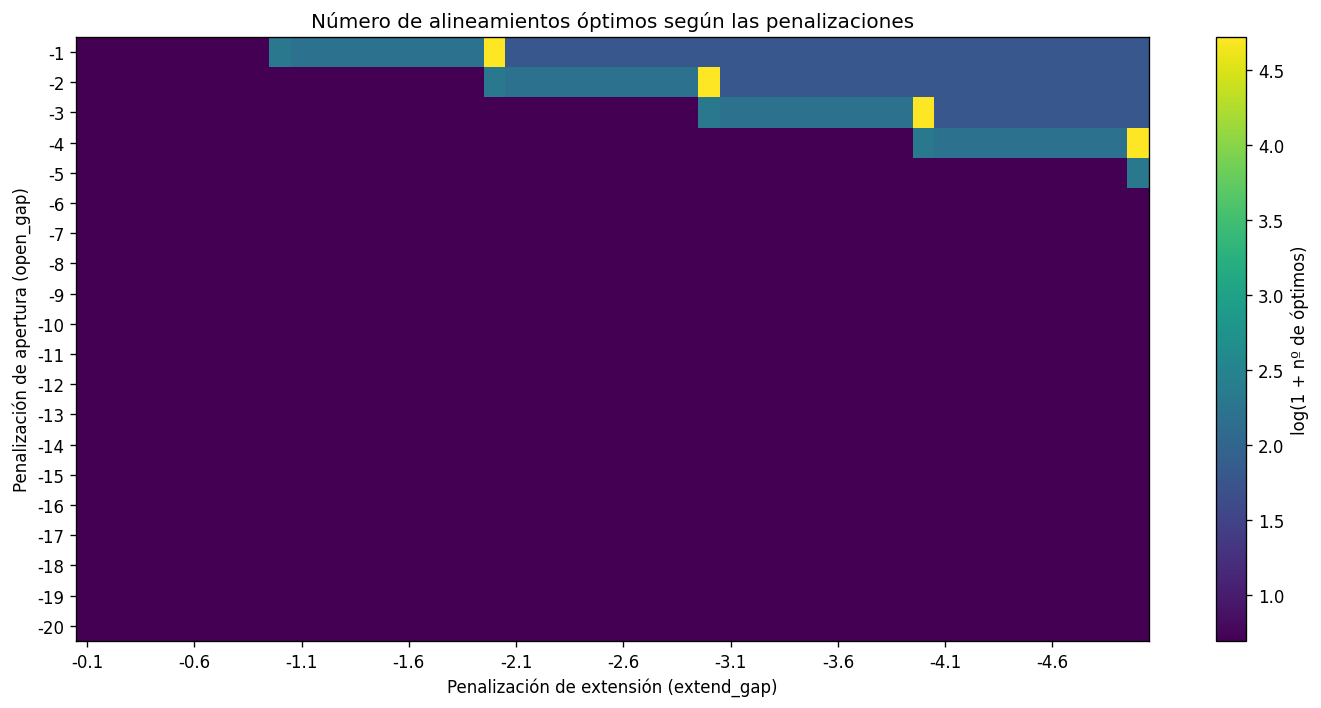

In [6]:
tabla_empates = df_grid.pivot(index="open_gap", columns="extend_gap", values="n_optimos")
tabla_empates = tabla_empates.sort_index(ascending=False).sort_index(axis=1, ascending=False)
valores_apertura = tabla_empates.index.to_numpy()
valores_extension = tabla_empates.columns.to_numpy()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(np.log1p(tabla_empates.values), aspect="auto", origin="upper", cmap="viridis")
pos_x = np.arange(0, len(valores_extension), 5)
ax.set_xticks(pos_x, labels=[f"{valores_extension[i]:.1f}" for i in pos_x])
ax.set_yticks(np.arange(len(valores_apertura)), labels=[f"{v:.0f}" for v in valores_apertura])
ax.set_xlabel("Penalización de extensión (extend_gap)")
ax.set_ylabel("Penalización de apertura (open_gap)")
ax.set_title("Número de alineamientos óptimos según las penalizaciones")
fig.colorbar(im, ax=ax, label="log(1 + nº de óptimos)")
plt.tight_layout()
plt.show()

### Localización matemática de la transición «múltiples empates → solución única»

Con este esquema compiten dos tipos de alineamiento global:

- **Un hueco de seis posiciones**, que conserva 8 coincidencias: $S_A = 8 + o + 5e$.
- **Dos huecos (4 y 2 posiciones)**, que conservan 8 coincidencias: $S_B = 8 + 2o + 4e$.

La igualdad $S_A = S_B$ se da cuando $8+o+5e = 8+2o+4e \Rightarrow \mathbf{o = e}$.
Como $S_A - S_B = e - o$:

- si $o < e$ (la apertura es **más** penalizada que la extensión) gana el hueco único ⇒ **una única solución óptima**;
- si $o = e$ hay empate entre ambas estrategias (y aparecen otras variantes) ⇒ **múltiples óptimos**;
- si $o > e$ (abrir es **más barato** que extender) se reparten los huecos de varias formas ⇒ **también múltiples óptimos**.

Primero se comprueba la frontera en un corte concreto (`extend_gap = -1`) y después se verifica sobre **toda la rejilla**.

In [7]:
def ejecutar_alineacion(apertura, extension):
    a = Align.PairwiseAligner()
    a.mode = "global"
    a.match_score = 1
    a.mismatch_score = 0
    a.open_gap_score = apertura
    a.extend_gap_score = extension
    return a.align(seq_sana, seq_paciente)

comparacion = []
for apertura in (-0.999, -1.0, -1.001):
    resultado = ejecutar_alineacion(apertura, -1.0)
    comparacion.append({"open_gap": apertura, "extend_gap": -1.0,
                        "n_optimos": len(resultado), "score": resultado.score})
display(pd.DataFrame(comparacion))

print("Solución única justo después de la frontera (open_gap = -1.001, extend_gap = -1):")
print(ejecutar_alineacion(-1.001, -1.0)[0])

o, e = -1.0, -1.0
print(f"En la frontera: S_A = {8 + o + 5*e:.1f}; S_B = {8 + 2*o + 4*e:.1f}")

,open_gap,extend_gap,n_optimos,score
0,-0.999,-1.0,8,2.002
1,-1.000,-1.0,9,2.000
2,-1.001,-1.0,1,1.999


Solución única justo después de la frontera (open_gap = -1.001, extend_gap = -1):
target            0 GCATGCATGCATGC 14
                  0 ||||||------|| 14
query             0 GCATGC------GC  8

En la frontera: S_A = 2.0; S_B = 2.0


In [8]:
df_grid["regimen"] = np.where(
    np.isclose(df_grid["open_gap"], df_grid["extend_gap"]), "o = e",
    np.where(df_grid["open_gap"] < df_grid["extend_gap"], "o < e", "o > e"))

resumen_regimen = df_grid.groupby("regimen")["n_optimos"].agg(
    combinaciones="size",
    con_solucion_unica=lambda s: int((s == 1).sum()),
    min_optimos="min",
    max_optimos="max")
display(resumen_regimen)

unica = df_grid["n_optimos"] == 1
regla = df_grid["open_gap"] < df_grid["extend_gap"]
print("¿'solución única' coincide con 'open_gap < extend_gap' en las "
      f"{len(df_grid)} combinaciones? ->", bool((unica == regla).all()))

,combinaciones,con_solucion_unica,min_optimos,max_optimos
regimen,,,,
o < e,895,895,1,1
o = e,5,0,9,9
o > e,100,0,5,111


¿'solución única' coincide con 'open_gap < extend_gap' en las 1000 combinaciones? -> True


**Interpretación.** El punto de «colapso» no es un único valor, sino la **recta $o = e$** del espacio de parámetros: a un lado (apertura más penalizada que la extensión) el alineador concentra los huecos en un bloque largo y devuelve una única solución; en la recta y al otro lado aparecen empates. La celda anterior comprueba esta regla con las 1000 combinaciones de la rejilla.

**Advertencia (nota importante del enunciado).** Convertir un concepto biológico en un problema de optimización puro es peligroso. En $o = e$ el modelo trata igual **un único evento de inserción/deleción** que **dos eventos** (da la misma puntuación), algo biológicamente poco razonable, porque un indel largo suele ser un solo suceso evolutivo. Además, el «número de óptimos» mide empates del esquema de puntuación, **no** la calidad biológica de los alineamientos: un esquema con más empates no es peor ni mejor por ello. Los valores de penalización deben justificarse con criterios biológicos (p. ej. apertura mucho más penalizada que la extensión), no solo buscando el punto donde el número de soluciones cambia.

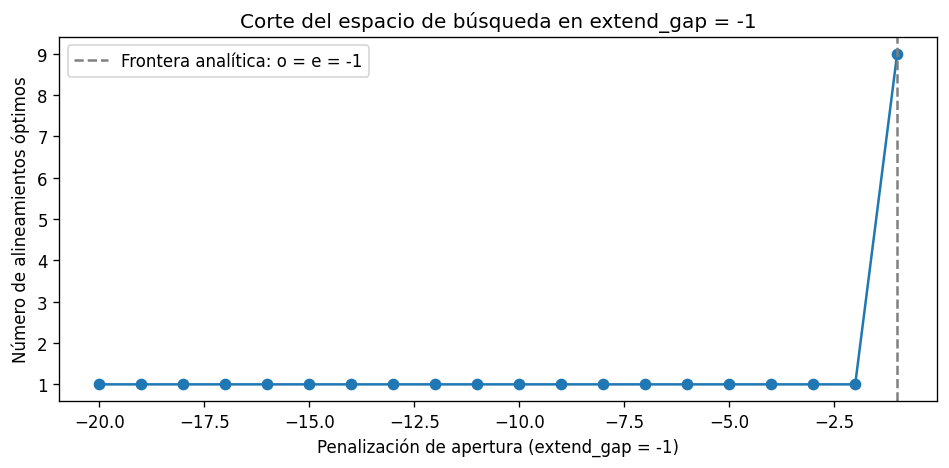

In [9]:
seccion = df_grid[df_grid["extend_gap"].eq(-1.0)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seccion["open_gap"], seccion["n_optimos"], marker="o")
ax.axvline(-1, linestyle="--", color="gray", label="Frontera analítica: o = e = -1")
ax.set_xlabel("Penalización de apertura (extend_gap = -1)")
ax.set_ylabel("Número de alineamientos óptimos")
ax.set_title("Corte del espacio de búsqueda en extend_gap = -1")
ax.legend()
plt.tight_layout()
plt.show()

### Demostración general de la frontera (más allá de «dos estrategias»)

Hasta aquí se compararon dos estrategias concretas. Para asegurar que **ninguna otra configuración** las supera, se razona sobre *todos* los alineamientos globales posibles.

**Notación.** Sea $T$ la secuencia larga (14) y $Q$ la corta (8). Un alineamiento tiene $p$ columnas de emparejamiento, de las cuales $M$ son coincidencias ($M\le p$). Sea $j$ el número de residuos de $Q$ frente a hueco; entonces $T$ tiene $6+j$ residuos frente a hueco y hay $G=6+2j$ columnas de hueco, agrupadas en $r$ tramos. Con $d = o-e$:

$$S \;=\; M + r\,o + (G-r)\,e \;=\; M + r\,d + G\,e \qquad (M\le 8-j)$$

**Caso $o<e$ ($d<0$): solución única.** Se compara cualquier alineamiento con el candidato $8+d+6e$ (un solo bloque, 8 coincidencias):

- Si $j\ge 1$, hay huecos en ambas secuencias y por tanto $r\ge 2$: $S\le (8-j)+2d+(6+2j)e = (8+d+6e) + d + j(2e-1) < 8+d+6e$, porque $d<0$ y $2e-1<0$.
- Si $j=0$ y $r\ge 2$: $S\le 8+2d+6e < 8+d+6e$.
- Si $j=0$, $r=1$ y $M\le 7$: $S\le 7+d+6e < 8+d+6e$.
- Solo queda $j=0$, $r=1$, $M=8$: borrar **un bloque contiguo de 6 posiciones** de $T$ de forma que quede exactamente $Q$. La celda siguiente comprueba que solo la posición de inicio $s=6$ lo consigue ⇒ **el óptimo existe y es único**.

**Caso $o=e$ ($d=0$): empates.** $S = M+Ge \le 8+6e + j(2e-1)$, así que el óptimo exige $j=0$ y $M=8$, y **cualquier** número de tramos $r$ da la misma puntuación. Basta con que existan alineamientos con $M=8$ y $r\ge2$ para tener más de un óptimo (la enumeración siguiente cuenta cuántos).

**Caso $o>e$ ($d>0$): abrir huecos sale más barato que alargarlos.** Ahora cada tramo adicional *suma* $d$, de modo que el bloque único de 6 deja de ser óptimo en cuanto existe un alineamiento con $M=8$ y más tramos. Aquí no hay una fórmula cerrada sencilla, así que se **enumeran exactamente todos los alineamientos** agrupándolos por clase $(M, r, G)$ con programación dinámica. Dentro de cada clase la puntuación es una función lineal de $(o,e)$, por lo que el número de óptimos para cualquier par de penalizaciones se obtiene sumando los contadores de las clases que alcanzan el máximo.

In [10]:
from collections import defaultdict

def clases_de_alineamiento(s1, s2):
    n, m = len(s1), len(s2)
    tab = [[defaultdict(lambda: defaultdict(int)) for _ in range(m + 1)] for _ in range(n + 1)]
    tab[0][0][None][(0, 0, 0)] = 1
    for i in range(n + 1):
        for j in range(m + 1):
            for ult, d in list(tab[i][j].items()):
                for (M, r, G), c in list(d.items()):
                    if i < n and j < m:
                        tab[i + 1][j + 1]["D"][(M + (s1[i] == s2[j]), r, G)] += c
                    if i < n:
                        tab[i + 1][j]["X"][(M, r + (ult != "X"), G + 1)] += c
                    if j < m:
                        tab[i][j + 1]["Y"][(M, r + (ult != "Y"), G + 1)] += c
    total = defaultdict(int)
    for d in tab[n][m].values():
        for clave, c in d.items():
            total[clave] += c
    return dict(total)

clases = clases_de_alineamiento(seq_sana, seq_paciente)
print(f"Alineamientos globales posibles: {sum(clases.values()):,} agrupados en {len(clases)} clases (M, r, G)")

inicios = [s for s in range(len(seq_sana) - 5) if seq_sana[:s] + seq_sana[s + 6:] == seq_paciente]
print("Posiciones de inicio válidas para un bloque único de 6 huecos:", inicios)

por_tramos = defaultdict(int)
for (M, r, G), c in clases.items():
    if M == 8 and G == 6:
        por_tramos[r] += c
print("Alineamientos con M=8 y G=6 según nº de tramos r:", dict(sorted(por_tramos.items())))

def n_optimos_exacto(o, e):
    mejor, cuenta = -np.inf, 0
    for (M, r, G), c in clases.items():
        s = M + o * r + e * (G - r)
        if s > mejor + 1e-9:
            mejor, cuenta = s, c
        elif abs(s - mejor) <= 1e-9:
            cuenta += c
    return mejor, cuenta

exacto = np.array([n_optimos_exacto(o, e)[1] for o, e in zip(df_grid["open_gap"], df_grid["extend_gap"])])
print("¿Recuento exacto == recuento de Biopython en toda la rejilla?", bool((exacto == df_grid["n_optimos"].to_numpy()).all()))

rng = np.random.default_rng(0)
fallos = 0
for _ in range(20000):
    o, e = -rng.uniform(0.001, 20), -rng.uniform(0.001, 5)
    _, cuenta = n_optimos_exacto(o, e)
    fallos += (cuenta == 1) != (o < e)
print("Fallos de la regla «solución única ⇔ open_gap < extend_gap» en 20000 pares aleatorios:", fallos)

Alineamientos globales posibles: 14,546,705 agrupados en 383 clases (M, r, G)
Posiciones de inicio válidas para un bloque único de 6 huecos: [6]
Alineamientos con M=8 y G=6 según nº de tramos r: {1: 1, 2: 8}
¿Recuento exacto == recuento de Biopython en toda la rejilla? True
Fallos de la regla «solución única ⇔ open_gap < extend_gap» en 20000 pares aleatorios: 0


**Lectura de los resultados.** Existe un único bloque de 6 huecos con 8 coincidencias, que comienza en el índice 6 (séptima posición). Hay otros 8 alineamientos con 8 coincidencias y dos tramos. En $o=e$ los 9 empatan. La enumeración exacta reproduce el recuento de Biopython en las 1.000 combinaciones de la rejilla. La regla también se cumple en los 20.000 pares adicionales de penalizaciones negativas probados al azar.

**Alcance.** La unicidad para $o<e$ se demuestra analíticamente. Para $o>e$ se verifica en los puntos explorados mediante recuento exacto de los alineamientos. La comprobación aleatoria aporta evidencia adicional. El resultado se refiere a estas dos secuencias, con coincidencia de 1, discrepancia de 0 y penalizaciones estrictamente negativas.


## Ejercicio 2 · Comparación «todos contra todos» de proteínas

Se comparan cinco homólogos reales de la hemoglobina subunidad alfa de humano, ratón, vaca, pollo y pez cebra. Se leen con `Bio.SeqIO`, se calculan las 25 puntuaciones globales con BLOSUM62 y se representa su matriz como mapa de calor. Después se repite con BLOSUM45 y PAM250.

**Origen de los datos.** Las secuencias proceden de UniProt, con las accesiones indicadas en el código. El archivo `proteinas_reales.fasta` incluido en la entrega permite repetir el análisis sin conexión. Si falta, se descarga desde `https://rest.uniprot.org/uniprotkb/<accesión>.fasta`. Se comprueban las cinco accesiones y las descripciones de las proteínas.


In [11]:
import urllib.request

fasta_real = Path("proteinas_reales.fasta")

accesiones = {
    "Humano":    "P69905",
    "Raton":     "P01942",
    "Vaca":      "P01966",
    "Pollo":     "P01994",
    "Pez_cebra": "Q90487",
}

def descargar_fasta_uniprot(accesion):
    url = f"https://rest.uniprot.org/uniprotkb/{accesion}.fasta"
    with urllib.request.urlopen(url, timeout=20) as respuesta:
        return respuesta.read().decode("utf-8")

if not fasta_real.exists():
    bloques = []
    for especie, acc in accesiones.items():
        texto = descargar_fasta_uniprot(acc)
        cabecera, *lineas = texto.strip().splitlines()
        assert "Hemoglobin subunit alpha" in cabecera, f"Proteína inesperada en {acc}"
        bloques.append(f">{especie}|{acc} {cabecera[1:]}\n" + "".join(lineas) + "\n")
    fasta_real.write_text("".join(bloques), encoding="utf-8")

registros = list(SeqIO.parse(fasta_real, "fasta"))
nombres = [r.id for r in registros]
n = len(registros)
assert n == 5, "Se requieren cinco secuencias"
assert nombres == [f"{especie}|{acc}" for especie, acc in accesiones.items()]
assert all("Hemoglobin subunit alpha" in r.description for r in registros)
print("Origen de los datos: secuencias reales de UniProt")
for r in registros:
    print(r.description)
    print("Longitud:", len(r.seq), "aminoácidos")


Origen de los datos: secuencias reales de UniProt
Humano|P69905 sp|P69905|HBA_HUMAN Hemoglobin subunit alpha OS=Homo sapiens OX=9606 GN=HBA1 PE=1 SV=2
Longitud: 142 aminoácidos
Raton|P01942 sp|P01942|HBA_MOUSE Hemoglobin subunit alpha OS=Mus musculus OX=10090 GN=Hba PE=1 SV=2
Longitud: 142 aminoácidos
Vaca|P01966 sp|P01966|HBA_BOVIN Hemoglobin subunit alpha OS=Bos taurus OX=9913 GN=HBA PE=1 SV=2
Longitud: 142 aminoácidos
Pollo|P01994 sp|P01994|HBA_CHICK Hemoglobin subunit alpha-A OS=Gallus gallus OX=9031 GN=HBAA PE=1 SV=2
Longitud: 142 aminoácidos
Pez_cebra|Q90487 sp|Q90487|HBA_DANRE Hemoglobin subunit alpha OS=Danio rerio OX=7955 GN=hbaa1 PE=2 SV=3
Longitud: 143 aminoácidos


### Matriz de puntuaciones con BLOSUM62

Se calcula la puntuación de cada par (incluida cada secuencia consigo misma) con las mismas penalizaciones de huecos (`-10` apertura, `-0.5` extensión), como en los apuntes.

In [12]:
def matriz_puntuaciones(registros, nombre_matriz):
    a = Align.PairwiseAligner()
    a.mode = "global"
    a.substitution_matrix = substitution_matrices.load(nombre_matriz)
    a.open_gap_score = -10
    a.extend_gap_score = -0.5
    ids = [r.id for r in registros]
    valores = np.zeros((len(registros), len(registros)))
    for i, ri in enumerate(registros):
        for j, rj in enumerate(registros):
            valores[i, j] = a.score(ri.seq, rj.seq)
    return pd.DataFrame(valores, index=ids, columns=ids)

matriz_blosum62 = matriz_puntuaciones(registros, "BLOSUM62")
print(f"Matriz BLOSUM62 ({n} × {n} = {n*n} puntuaciones)")
display(matriz_blosum62)
assert matriz_blosum62.shape == (5, 5)
assert np.allclose(matriz_blosum62.values, matriz_blosum62.values.T)

Matriz BLOSUM62 (5 × 5 = 25 puntuaciones)


,Humano|P69905,Raton|P01942,Vaca|P01966,Pollo|P01994,Pez_cebra|Q90487
Humano|P69905,733.0,648.0,644.0,523.0,382.0
Raton|P01942,648.0,737.0,639.0,542.0,381.0
Vaca|P01966,644.0,639.0,726.0,528.0,386.0
Pollo|P01994,523.0,542.0,528.0,737.0,367.0
Pez_cebra|Q90487,382.0,381.0,386.0,367.0,725.0


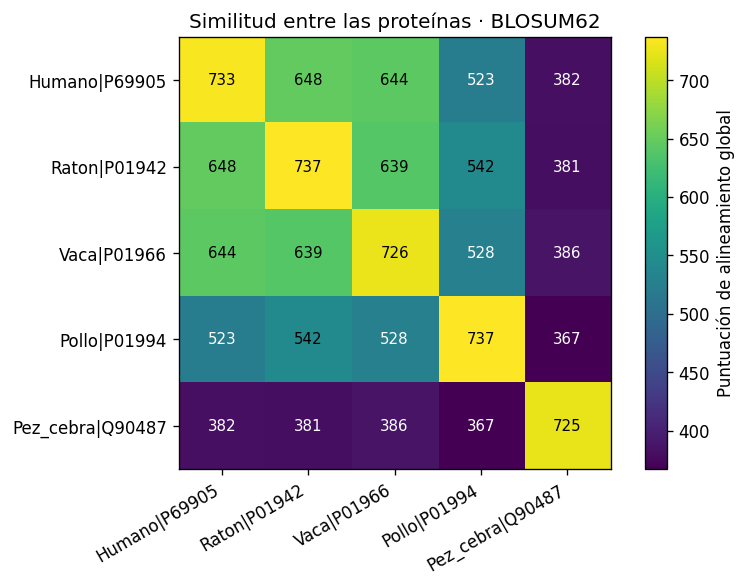

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(matriz_blosum62.values, cmap="viridis")
ax.set_xticks(range(n), nombres, rotation=30, ha="right")
ax.set_yticks(range(n), nombres)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{matriz_blosum62.iloc[i, j]:.0f}", ha="center", va="center",
                color="white" if im.norm(matriz_blosum62.iloc[i, j]) < 0.45 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Puntuación de alineamiento global")
ax.set_title("Similitud entre las proteínas · BLOSUM62")
plt.tight_layout()
plt.show()

### Comparación con otras matrices de sustitución

Se repite el cálculo con **BLOSUM45** y **PAM250**. Cada matriz tiene su propia escala, por lo que **no se comparan los valores absolutos**. Como comparación **exploratoria** se divide cada puntuación por la menor autopuntuación del par:

$$S_{norm}(i,j)=\frac{S(i,j)}{\min\big(S(i,i),\,S(j,j)\big)}$$

**Cautela sobre esta medida.** No es una normalización estándar ni garantiza un índice de similitud acotado o válido para cualquier matriz o par de proteínas: depende de la composición de aminoácidos (la autopuntuación cambia con ella) y de las penalizaciones de huecos. Solo sirve para tener una escala aproximada con la diagonal en 1, y el código comprueba si en estos datos queda por debajo de 1. Para no depender de ella, la comparación principal entre matrices se hace además con medidas **que no dependen de la escala**: el **orden de similitud** y la **correlación de rangos de Spearman** entre las puntuaciones de los pares.

,Matriz,Media (bruta),Mín (bruta),Máx (bruta),Media (normalizada),Mín (normalizada),Máx (normalizada)
0,BLOSUM62,504.0,367.0,648.0,0.692,0.506,0.887
1,BLOSUM45,605.5,450.0,772.0,0.699,0.522,0.891
2,PAM250,499.7,390.0,611.0,0.756,0.578,0.931


BLOSUM62  máx. normalizada fuera de la diagonal = 0.887 (<= 1)
BLOSUM45  máx. normalizada fuera de la diagonal = 0.891 (<= 1)
PAM250    máx. normalizada fuera de la diagonal = 0.931 (<= 1)

Correlación de rangos de Spearman entre las puntuaciones de los pares:


,BLOSUM62,BLOSUM45,PAM250
BLOSUM62,1.000,1.000,0.964
BLOSUM45,1.000,1.000,0.964
PAM250,0.964,0.964,1.000


Pares ordenados de más a menos similar (BLOSUM62):


,BLOSUM62,BLOSUM45,PAM250
Humano|P69905 - Raton|P01942,648.0,772.0,609.0
Humano|P69905 - Vaca|P01966,644.0,768.0,611.0
Raton|P01942 - Vaca|P01966,639.0,761.0,600.0
Raton|P01942 - Pollo|P01994,542.0,647.0,538.0
Vaca|P01966 - Pollo|P01994,528.0,633.0,516.0
Humano|P69905 - Pollo|P01994,523.0,629.0,525.0
Vaca|P01966 - Pez_cebra|Q90487,386.0,468.0,404.0
Humano|P69905 - Pez_cebra|Q90487,382.0,465.0,405.0
Raton|P01942 - Pez_cebra|Q90487,381.0,462.0,399.0
Pollo|P01994 - Pez_cebra|Q90487,367.0,450.0,390.0


Orden de similitud (de más a menos parecida a Humano|P69905):
  BLOSUM62  ['Raton|P01942', 'Vaca|P01966', 'Pollo|P01994', 'Pez_cebra|Q90487']
  BLOSUM45  ['Raton|P01942', 'Vaca|P01966', 'Pollo|P01994', 'Pez_cebra|Q90487']
  PAM250    ['Vaca|P01966', 'Raton|P01942', 'Pollo|P01994', 'Pez_cebra|Q90487']


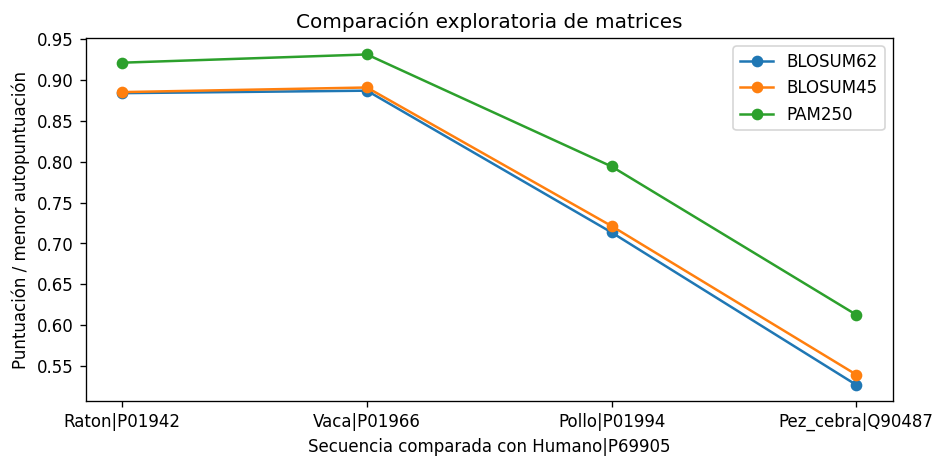

In [14]:
def normalizar(df):
    diag = np.diag(df.values)
    return pd.DataFrame(df.values / np.minimum.outer(diag, diag), index=df.index, columns=df.columns)

matrices = {"BLOSUM62": matriz_blosum62,
            "BLOSUM45": matriz_puntuaciones(registros, "BLOSUM45"),
            "PAM250": matriz_puntuaciones(registros, "PAM250")}
normalizadas = {k: normalizar(v) for k, v in matrices.items()}

indices_sup = np.triu_indices(n, k=1)
resumen = []
for nombre, df in matrices.items():
    bruto = df.values[indices_sup]
    norm = normalizadas[nombre].values[indices_sup]
    resumen.append({"Matriz": nombre,
                    "Media (bruta)": bruto.mean(), "Mín (bruta)": bruto.min(), "Máx (bruta)": bruto.max(),
                    "Media (normalizada)": norm.mean(), "Mín (normalizada)": norm.min(), "Máx (normalizada)": norm.max()})
display(pd.DataFrame(resumen).round(3))

for nombre, df in normalizadas.items():
    fuera = df.values[indices_sup]
    print(f"{nombre:9s} máx. normalizada fuera de la diagonal = {fuera.max():.3f} "
          f"({'<= 1' if fuera.max() <= 1 else 'SUPERA 1: la medida no es una similitud acotada aquí'})")

pares = [f"{nombres[i]} - {nombres[j]}" for i, j in zip(*indices_sup)]
tabla_pares = pd.DataFrame({k: v.values[indices_sup] for k, v in matrices.items()}, index=pares)
print("\nCorrelación de rangos de Spearman entre las puntuaciones de los pares:")
display(tabla_pares.rank().corr().round(3))
print("Pares ordenados de más a menos similar (BLOSUM62):")
display(tabla_pares.sort_values("BLOSUM62", ascending=False).round(1))

referencia = nombres[0]
print(f"Orden de similitud (de más a menos parecida a {referencia}):")
for nombre, df in matrices.items():
    orden = df.loc[referencia].drop(referencia).sort_values(ascending=False).index.tolist()
    print(f"  {nombre:9s}", orden)

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, df in normalizadas.items():
    ax.plot(range(1, n), [df.iloc[0, j] for j in range(1, n)], marker="o", label=nombre)
ax.set_xticks(range(1, n), nombres[1:])
ax.set_xlabel(f"Secuencia comparada con {referencia}")
ax.set_ylabel("Puntuación / menor autopuntuación")
ax.set_title("Comparación exploratoria de matrices")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** Con BLOSUM62, humano–ratón obtiene la mayor puntuación entre especies distintas (648) y pollo–pez cebra la menor (367). Las tres parejas de mamíferos tienen puntuaciones superiores a las parejas que incluyen pollo o pez cebra. La matriz es simétrica y las autopuntuaciones de la diagonal son las mayores en estos datos.

BLOSUM45 conserva el mismo orden de los diez pares que BLOSUM62 (Spearman = 1). PAM250 da un orden parecido (Spearman ≈ 0,964), aunque sitúa humano–vaca por delante de humano–ratón. La normalización por la menor autopuntuación es un apoyo visual exploratorio. La comparación de rangos permite estudiar la estabilidad del orden entre matrices.

**Limitaciones.** La puntuación depende de la matriz y de las penalizaciones de huecos elegidas (−10 y −0,5). El estudio de una familia de proteínas permite observar conservación de secuencias. Para establecer relaciones evolutivas entre especies se necesitaría un análisis filogenético más amplio.

**Aportaciones adicionales.** Secuencias reales identificadas por accesión, validación del FASTA, comprobación de simetría y tamaño de la matriz, y comparación de rangos entre tres matrices de sustitución.


## Ejercicio 3 · Escalabilidad de los alineamientos

Se generan pares de secuencias de ADN de **100, 500, 1000, 2000 y 5000** bases con `random` y semilla fija. El tiempo se mide con `time.perf_counter` (alta resolución, en ms) y se reporta la **mediana** de varias repeticiones. Se miden dos operaciones:

- `.score()`: coste de obtener solo la puntuación óptima.
- `.align()` (recuperando el primer alineamiento): coste de **alinear** el par, que incluye el rastreo inverso. No se enumeran todos los óptimos (`len()` sobre el resultado) porque su número puede ser enorme.

In [15]:
random.seed(42)
longitudes = [100, 500, 1000, 2000, 5000]

def adn_aleatorio(longitud):
    return "".join(random.choices("ACGT", k=longitud))

alineador_tiempo = Align.PairwiseAligner()
alineador_tiempo.mode = "global"
alineador_tiempo.match_score = 1
alineador_tiempo.mismatch_score = -1
alineador_tiempo.open_gap_score = -2
alineador_tiempo.extend_gap_score = -0.5

tiempos = []
for longitud in longitudes:
    a, b = adn_aleatorio(longitud), adn_aleatorio(longitud)

    t_score = []
    for _ in range(3):
        inicio = perf_counter()
        puntuacion = alineador_tiempo.score(a, b)
        t_score.append((perf_counter() - inicio) * 1000)

    t_align = []
    for _ in range(3):
        inicio = perf_counter()
        primer_alineamiento = alineador_tiempo.align(a, b)[0]
        t_align.append((perf_counter() - inicio) * 1000)

    tiempos.append({"longitud": longitud,
                    "score_mediana_ms": np.median(t_score),
                    "score_min_ms": np.min(t_score),
                    "score_max_ms": np.max(t_score),
                    "align_mediana_ms": np.median(t_align),
                    "align_min_ms": np.min(t_align),
                    "align_max_ms": np.max(t_align),
                    "score": puntuacion})

df_tiempos = pd.DataFrame(tiempos)
display(df_tiempos.round(3))

,longitud,score_mediana_ms,score_min_ms,score_max_ms,align_mediana_ms,align_min_ms,align_max_ms,score
0,100,0.034,0.032,0.053,0.211,0.176,0.285,-5.5
1,500,0.812,0.801,0.813,4.413,4.309,4.539,-6.0
2,1000,3.629,3.219,3.673,17.870,17.551,17.947,-8.5
3,2000,13.837,13.651,14.427,69.409,68.481,71.292,5.0
4,5000,89.863,89.166,92.408,465.648,465.175,505.144,-5.0


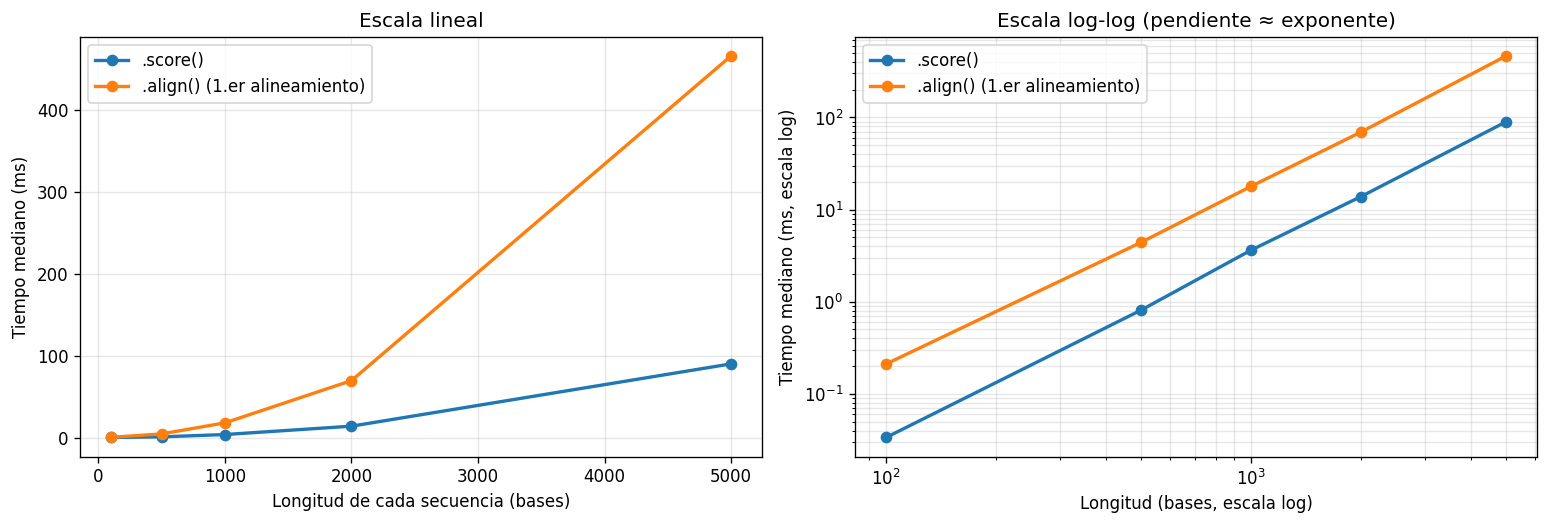

Exponente empírico de score_mediana_ms: 2.02  (cuadrático teórico = 2)
Exponente empírico de align_mediana_ms: 1.97  (cuadrático teórico = 2)
Longitud ×50 -> tiempo de .score() ×2672 (si fuera exactamente cuadrático: ×2500)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for columna, etiqueta in (("score_mediana_ms", ".score()"), ("align_mediana_ms", ".align() (1.er alineamiento)")):
    axes[0].plot(df_tiempos["longitud"], df_tiempos[columna], marker="o", linewidth=2, label=etiqueta)
    axes[1].loglog(df_tiempos["longitud"], df_tiempos[columna], marker="o", linewidth=2, label=etiqueta)

axes[0].set_xlabel("Longitud de cada secuencia (bases)")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].set_title("Escala lineal")
axes[1].set_xlabel("Longitud (bases, escala log)")
axes[1].set_ylabel("Tiempo mediano (ms, escala log)")
axes[1].set_title("Escala log-log (pendiente ≈ exponente)")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
plt.show()

logs_l = np.log(df_tiempos["longitud"].to_numpy(dtype=float))
pendientes = {}
for columna in ("score_mediana_ms", "align_mediana_ms"):
    pendientes[columna] = np.polyfit(logs_l, np.log(df_tiempos[columna].to_numpy()), 1)[0]
    print(f"Exponente empírico de {columna}: {pendientes[columna]:.2f}  (cuadrático teórico = 2)")

factor_long = df_tiempos["longitud"].iloc[-1] / df_tiempos["longitud"].iloc[0]
factor_tiempo = df_tiempos["score_mediana_ms"].iloc[-1] / df_tiempos["score_mediana_ms"].iloc[0]
print(f"Longitud ×{factor_long:.0f} -> tiempo de .score() ×{factor_tiempo:.0f} "
      f"(si fuera exactamente cuadrático: ×{factor_long**2:.0f})")

### Extrapolación a volúmenes grandes

El enunciado pregunta si el *pipeline* escalará de 100 a 1 millón de datos. Con el exponente empírico se estiman dos escenarios, **solo como orden de magnitud** (la extrapolación supone que el comportamiento se mantiene y no considera la memoria ni la caché).

In [17]:
exp = pendientes["align_mediana_ms"]
t_ref = df_tiempos["align_mediana_ms"].iloc[-1]
l_ref = df_tiempos["longitud"].iloc[-1]

t_a_ms = t_ref * (1_000_000 / l_ref) ** exp
print(f"A) Un alineamiento de 1.000.000 x 1.000.000 bases (.align()): ~{t_a_ms/1000/3600:,.1f} horas")
print(f"   Celdas de la matriz de programación dinámica: {1_000_000 * 1_000_000:.1e} (O(N·M) en memoria si se guarda el rastreo)")

t_b_ms = df_tiempos["align_mediana_ms"].iloc[0] * 1_000_000
print(f"B) 1.000.000 de pares de 100 bases, uno tras otro: ~{t_b_ms/1000/3600:,.1f} horas (un solo núcleo)")

A) Un alineamiento de 1.000.000 x 1.000.000 bases (.align()): ~4.3 horas
   Celdas de la matriz de programación dinámica: 1.0e+12 (O(N·M) en memoria si se guarda el rastreo)
B) 1.000.000 de pares de 100 bases, uno tras otro: ~0.1 horas (un solo núcleo)


**Interpretación.** Al duplicar la longitud, el tiempo se multiplica aproximadamente por cuatro: la matriz de programación dinámica para secuencias de longitudes $N$ y $M$ tiene $N\times M$ celdas, así que para secuencias igual de largas el coste es $O(N^2)$ y el exponente empírico del ajuste log-log queda próximo a 2. Las variaciones respecto a 2 se deben al ordenador, a la caché y a la sobrecarga fija de las secuencias cortas. `.align()` cuesta algo más que `.score()` porque además realiza el rastreo inverso y construye el alineamiento.

**Consecuencia para un ingeniero de datos.** Crecer en *número* de pares escala linealmente (escenario B: viable, paralelizable), pero crecer en *longitud* escala cuadráticamente (escenario A: muy exigente en tiempo y memoria con el método utilizado). Para volúmenes grandes se recurre a métodos heurísticos (BLAST, FASTA), a paralelismo o a alineamientos con banda.

**Aportaciones adicionales.** Semilla reproducible; mediana de varias repeticiones; medición separada de `.score()` y `.align()`; ajuste log-log del exponente; extrapolación explícita.

## Conclusiones generales

0. Needleman-Wunsch y Smith-Waterman, programados en Python puro, reproducen las puntuaciones de Biopython; el alineamiento global recorre las cadenas completas y el local recupera solo la región más similar.
1. Los parámetros de apertura y extensión de huecos influyen en la puntuación y en el número de alineamientos óptimos. La transición entre múltiples empates y solución única es la recta $o = e$: demostrada analíticamente para $o<e$, y verificada mediante recuento exacto en los 1.000 puntos de la rejilla y en 20.000 pares adicionales de penalizaciones negativas. Depende del esquema de puntuación, no solo de las secuencias.
2. La comparación de proteínas homólogas con BLOSUM62 resume la similitud de cada pareja en una matriz simétrica. El resultado depende de la matriz de sustitución y de las penalizaciones; las matrices se comparan mejor con medidas independientes de la escala (orden de los pares, correlación de Spearman) que con la normalización exploratoria por autopuntuación.
3. El coste de un alineamiento exacto crece de forma cuadrática con la longitud, lo que limita su uso a secuencias de tamaño moderado.